# 06 · Path-linearized vs frozen round map

In [ ]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # repo root when run from notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from eosfl import obs
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
def edge_line(ax, y=1.0):
    ax.axhline(y, color="k", lw=0.8)
AL = {np.inf: "α=∞ (IID)", 1.0: "α=1", 0.1: "α=0.1"}

In [ ]:
runs = obs.load_runs("fedavg_path"); traj = obs.load_traj("fedavg_path")
meas = traj[traj[["tau_max", "tau_path", "tau_path_min", "tau_min"]].notna().any(axis=1)].copy()
meas["frozen_ok"] = meas.tau_min.notna() & meas.tau_max.notna()
meas["path_ok"] = meas.tau_path_min.notna() & meas.tau_path.notna()
print("measurements per run with both ends solved (frozen / path):")
display(meas.groupby(["alpha", "local_steps"])[["frozen_ok", "path_ok"]].agg(["sum", "count"]))

measurements per run with both ends solved (frozen / path):


frozen_ok       path_ok      
                        sum count     sum count
alpha local_steps                              
0.1   1                   5     6       5     6
      2                   6     6       5     6
      5                   6     6       4     6
      10                  5     6       3     6
inf   1                   5     6       5     6
      2                   6     6       6     6
      5                   6     6       5     6
      10                  1     6       5     6

## 1. Equilibrium (median of the last 30% of valid measurements)

In [ ]:
cols = ["alpha", "local_steps", "eq_sharp_norm", "eq_client_norm", "eq_ceff_frozen", "eq_ceff_path"]
t = runs.sort_values(["alpha", "local_steps"])[cols].copy()
t["path − frozen"] = t.eq_ceff_path - t.eq_ceff_frozen
t

,alpha,local_steps,eq_sharp_norm,eq_client_norm,eq_ceff_frozen,eq_ceff_path,path − frozen
1,0.1,1,1.086,1.304,1.083,1.083,4.023e-07
2,0.1,2,1.029,1.194,1.077,1.015,-6.155e-02
3,0.1,5,1.012,1.168,1.078,1.063,-1.421e-02
0,0.1,10,1.003,1.140,1.076,1.020,-5.618e-02
5,inf,1,1.085,1.171,1.099,1.099,-3.316e-07
6,inf,2,1.072,1.138,1.080,1.035,-4.478e-02
7,inf,5,1.077,1.139,1.091,1.077,-1.332e-02
4,inf,10,1.081,1.138,1.056,1.020,-3.583e-02


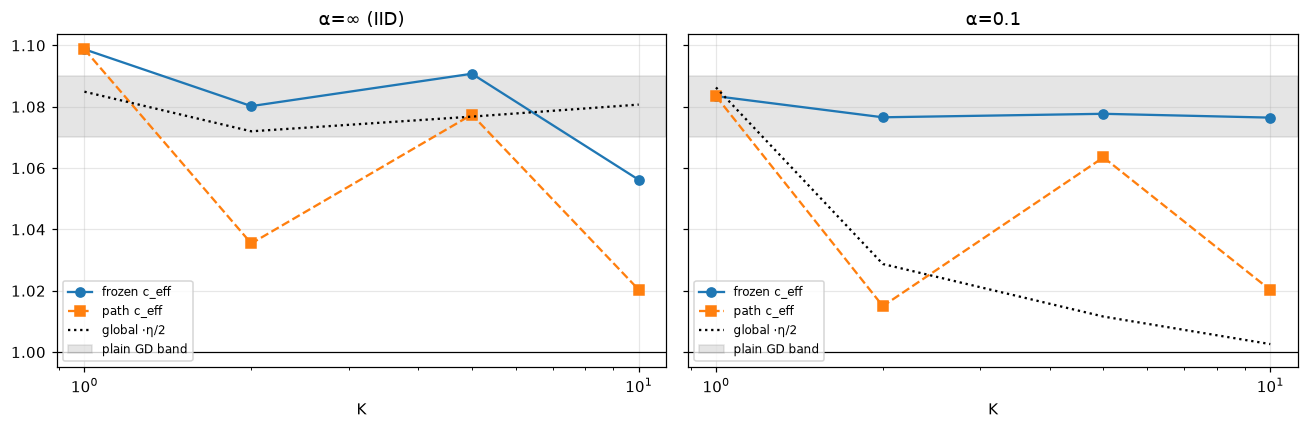

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, a in zip(axes, [np.inf, 0.1]):
    r = runs[runs.alpha == a].sort_values("local_steps")
    ax.plot(r.local_steps, r.eq_ceff_frozen, "o-", label="frozen c_eff")
    ax.plot(r.local_steps, r.eq_ceff_path, "s--", label="path c_eff")
    ax.plot(r.local_steps, r.eq_sharp_norm, "k:", label="global ·η/2")
    ax.axhspan(1.07, 1.09, color="grey", alpha=0.2, label="plain GD band"); edge_line(ax)
    ax.set_xscale("log"); ax.set_xlabel("K"); ax.set_title(AL[a]); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2. Over training (valid measurements only)

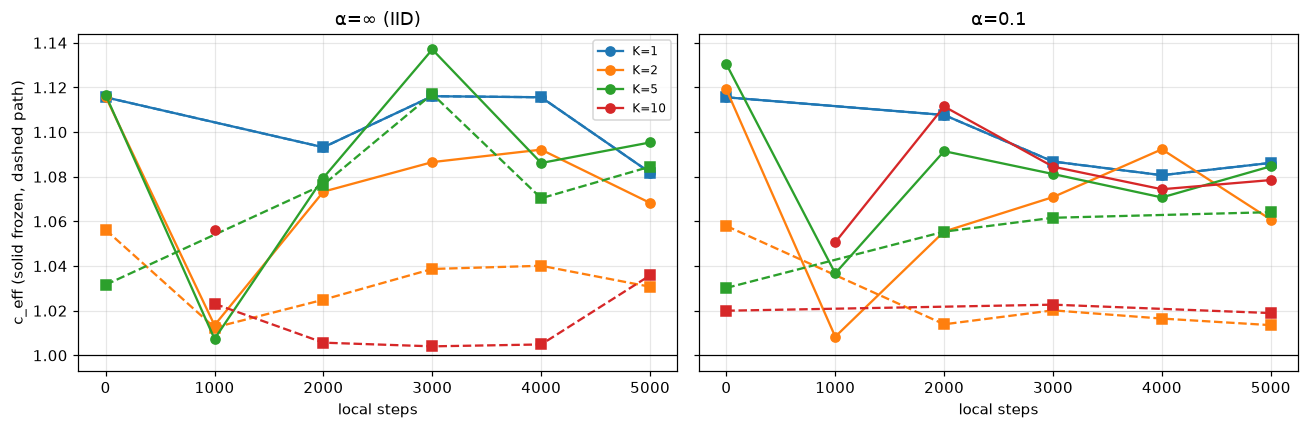

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, a in zip(axes, [np.inf, 0.1]):
    for K, g in meas[meas.alpha == a].groupby("local_steps"):
        f = g[g.frozen_ok]; line, = ax.plot(f.steps, f.ceff_frozen, "o-", label=f"K={K}")
        q = g[g.path_ok]; ax.plot(q.steps, q.ceff_path, "s--", color=line.get_color())
    edge_line(ax); ax.set_title(AL[a]); ax.set_xlabel("local steps")
axes[0].set_ylabel("c_eff (solid frozen, dashed path)"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. Which end of the spectrum carries the growth

For even K the frozen map's instability is a very negative τ_min. For odd K it is τ_max > 2. Compare with the path map at equilibrium (steps ≥ 3000).

In [ ]:
tail = meas[meas.steps >= meas.steps.max() * 0.6]
ends = tail.groupby(["alpha", "local_steps"])[["tau_min", "tau_path_min", "tau_max", "tau_path"]].median()
ends.columns = ["frozen τ_min", "path Re τ_min", "frozen τ_max", "path Re τ_max"]
ends.round(3)

frozen τ_min  path Re τ_min  frozen τ_max  path Re τ_max
alpha local_steps                                                          
0.1   1                  -0.161         -0.161         2.172          2.172
      2                  -0.304         -0.036         0.892          0.898
      5                  -0.568         -0.035         3.123          2.808
      10                 -3.299         -0.129         0.977          1.013
inf   1                  -0.133         -0.132         2.201          2.201
      2                  -0.376         -0.139         0.979          0.979
      5                  -1.036         -0.054         3.393          3.183
      10                    NaN         -0.102           NaN          1.503

## Conclusions

1. **Sanity:** at K = 1 path and frozen agree exactly.
2. **Path ≤ frozen at every K > 1, and never below the edge.** At equilibrium the path c_eff is ≈1.015–1.08: the real round is at or slightly above marginal stability per step.
3. **The gap depends on the parity of K.** Odd K (K = 5): path ≈ frozen − 0.01 to 0.02 (≈1.06–1.085), so the per-step law ≈1.08 holds along the real path. Even K (K = 2, 10): path ≈ 1.015–1.035, well below frozen ≈1.08.
4. **Mechanism (section 3).** At even K the frozen map's huge negative τ_min (non-oscillating growth: the overshoot flips sign K times and comes back amplified) almost disappears along the real path (path τ_min ≈ −0.03 to −0.16 vs frozen −0.3 to −3.3). At odd K the oscillating end (τ_max > 2) survives with a small reduction. Interpretation (hypothesis): a client's EoS oscillation has period 2. For odd K it leaves the round on the opposite side and shows up as a round-level oscillation that persists; for even K it returns to the same side and the curvature change along the path cancels most of the compounding.
5. **So:** clients do partly flatten within a round. The per-step c_eff ≈ 1.08 of notebook 05 is a property of the frozen linearization; along the real path it holds for odd K and relaxes toward 1 for even K.

**Caveats.** One seed, 5k steps, only 2–3 valid measurements in the equilibrium window per run. 10 of 48 path and 8 of 48 frozen measurements failed under the solver cap (frozen at α = ∞, K = 10 failed 5 of 6 times, so its equilibrium is not available; equilibria use only measurements in the last 30% of steps). The dips below 0.9 in older plots came from measurements with one end missing and are not physical.